### Practice

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data_setpath = 'Placement_Data_Full_Class.csv'

df = pd.read_csv(data_setpath)
df.head()

,Sno,Gender,10th %,SSC Board,12th %,HSC Board,12th Stream,Degree %,Degree stream,Work exp,specialisation,Mba %,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,Mkt&Fin,55.50,Placed,425000.0


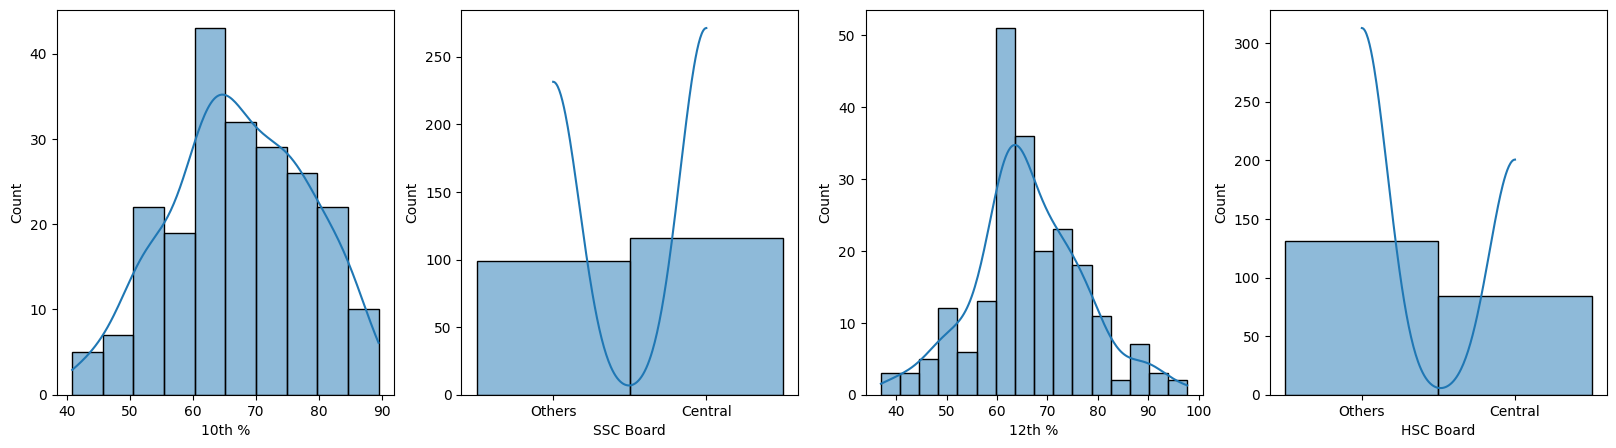

In [5]:
# plot graphs of data

plt.figure(figsize=(20, 5))

columns = ['10th %', 'SSC Board', '12th %', 'HSC Board']

# enumerate funciton is used to get the index and value of each column in the list
for i, col in enumerate(columns):

    # create a subplot for each column 1 mean one row and len(columns) mean number of columns and the index of the column is used to place the subplot in the correct position
    plt.subplot(1, len(columns), i + 1)
    sns.histplot(df[col], kde=True)



### Task 1

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
data_setpath = 'insurance.csv'

df = pd.read_csv(data_setpath)
df.shape

(1338, 7)

In [85]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


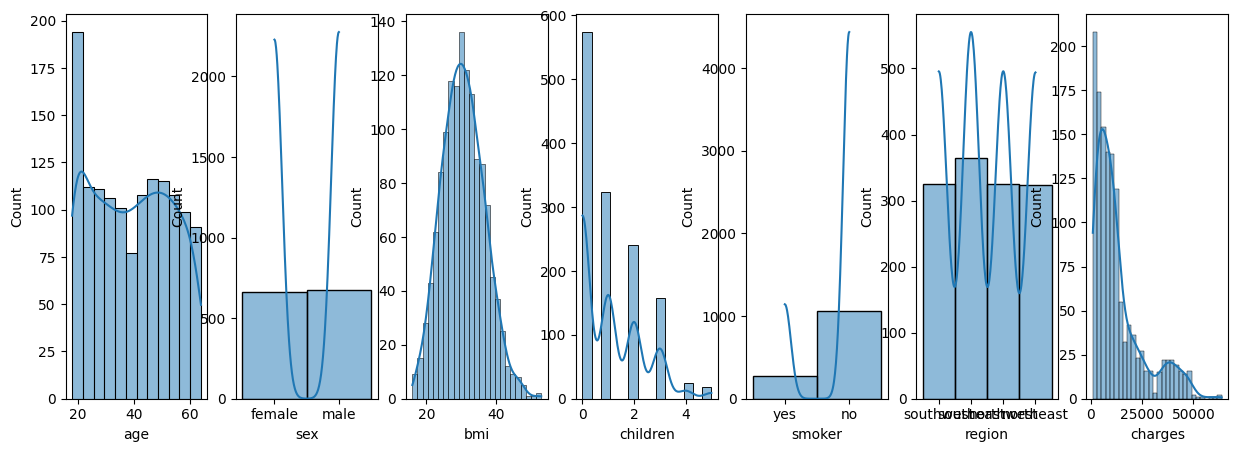

In [ ]:
plt.figure(figsize=(15, 5))

columns = ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

# enumerate funciton is used to get the index and value of each column in the list
for i, col in enumerate(columns):

    # create a subplot for each column 1 mean one row and len(columns) mean 
    # number of columns and the index of the column is used to place the subplot in the correct position
    plt.subplot(1, len(columns), i + 1)
    sns.histplot(df[col], kde=True)

In [10]:
# skewness for numerical columns
df[['age', 'bmi', 'children', 'charges']].skew()

age         0.055673
bmi         0.284047
children    0.938380
charges     1.515880
dtype: float64

In [ ]:
# lets take the age as it is more close to normal distrubution
col = 'age'
df[col].describe()

count    1338.000000
mean       39.207025
std        14.049960
min        18.000000
25%        27.000000
50%        39.000000
75%        51.000000
max        64.000000
Name: age, dtype: float64

In [12]:
# now lets calculate the z-score for the age column and find the outliers

mean = df[col].mean()
std = df[col].std()

df['z_score'] = (df[col] - mean) / std
df[[col, 'z_score']].sample(20)

,age,z_score
455,59,1.408757
271,50,0.768185
370,61,1.551106
896,43,0.269963
1203,51,0.839360
746,34,-0.370608
425,45,0.412313
967,44,0.341138
888,22,-1.224703
204,46,0.483487


In [13]:
# find the outliers in the age column using z-score method
df['outliers'] = np.abs(df['z_score']) > 3
df['outliers'].value_counts()


outliers
False    1338
Name: count, dtype: int64

In [14]:

col = 'bmi'
mean = df[col].mean()
std = df[col].std()

df['z_score'] = (df[col] - mean) / std
df[[col, 'z_score']].sample(20)
# find the outliers in the age column using z-score method
df['outliers'] = np.abs(df['z_score']) > 3
df['outliers'].value_counts()

outliers
False    1334
True        4
Name: count, dtype: int64

In [ ]:
# print outliers where true
df[df['outliers'] == True]

,age,sex,bmi,children,smoker,region,charges,z_score,outliers
116,58,male,49.06,0,no,southeast,11381.3254,3.016733,True
847,23,male,50.38,1,no,southeast,2438.0552,3.233191,True
1047,22,male,52.58,1,yes,southeast,44501.3982,3.593954,True
1317,18,male,53.13,0,no,southeast,1163.4627,3.684145,True


In [16]:
# Now capping the outliers in the charges column using z-score method

lower_limit = mean - 3 * std
upper_limit = mean + 3 * std

df['bmi_capped'] = np.where(df['bmi'] > upper_limit, upper_limit, df['bmi'])
df['bmi_capped'] = np.where(df['bmi_capped'] < lower_limit, lower_limit, df['bmi_capped'])

# now check weather capping works or not
#loc function is used to select rows and columns by label and index
df.loc[df['bmi'] > upper_limit, ['bmi', 'bmi_capped']].head(10)

,bmi,bmi_capped
116,49.06,48.957958
847,50.38,48.957958
1047,52.58,48.957958
1317,53.13,48.957958


### Task 2

In [17]:
# The right skew coloum here is charges 
df['charges'].skew()

np.float64(1.5158796580240388)

In [ ]:
# Now z-score method is not suitable for right skewed data, 
# so we will use IQR method to find the outliers in the charges column

col = 'charges'

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]
outliers.shape


(139, 10)

In [19]:


# 1. OVERVIEW OF ALL POSSIBLE OUTLIER HANDLING METHODS:
#    Method A (Removal/Trimming): Delete all rows containing outliers.
#    Method B (Capping / Winsorization): Clamp extreme high/low values to a boundary limit.
#    Method C (Predictive Imputation): Treat outliers as missing and use an ML model to predict them.

# 2. WHY WE REJECTED REMOVAL (TRIMMING):
#    IQR found 139 outliers in the 'charges' column because medical costs are right-skewed.
#    If we delete them, we lose 139 rows of real-world patient data, shrinking our dataset.
#    These high costs are not typos or errors; they are real patients with major medical bills.
#    Therefore, deleting them discards crucial high-risk financial information.

# 3. WHY WE REJECTED PREDICTIVE IMPUTATION (MODEL PREDICTION):
#    Using a machine learning model to predict and replace outlier values causes "regression to the mean".
#    The model would look at standard age/BMI and severely underpredict extreme, rare medical bills.
#    It also adds unnecessary complexity.

# 4. WHY WE CHOSE CAPPING (WINSORIZATION) AS THE BEST METHOD:
#    Zero Data Loss: Keeps all 1338 rows completely intact.
#    Stops Skewness Distortion: Prevents the 139 extreme high-cost bills from breaking the regression math.
#    Logical Balance: It respects that these extreme cases happened, but safely caps their 



df['charges_capped'] = np.where(df['charges'] > upper_limit, upper_limit, df['charges'])
df['charges_capped'] = np.where(df['charges_capped'] < lower_limit, lower_limit, df['charges_capped'])

# now check weather capping works or not
df.loc[df['charges'] > upper_limit, ['charges', 'charges_capped']]

,charges,charges_capped
14,39611.75770,34489.350562
19,36837.46700,34489.350562
23,37701.87680,34489.350562
29,38711.00000,34489.350562
30,35585.57600,34489.350562
...,...,...
1300,62592.87309,34489.350562
1301,46718.16325,34489.350562
1303,37829.72420,34489.350562
1313,36397.57600,34489.350562


### Task 3

In [20]:

# Analyze skewness for 'age' Symmetric (Neither left nor right skewed), but Uniform/Not Normal.
age_skew = df['age'].skew()
print(f'Age Skewness: {age_skew:.6f}')


# Check for outliers using IQR on 'age'
Q1_age = df['age'].quantile(0.25)
Q3_age = df['age'].quantile(0.75)
IQR_age = Q3_age - Q1_age

lower_age = Q1_age - 1.5 * IQR_age
upper_age = Q3_age + 1.5 * IQR_age

# Identify outliers
age_outliers = df[(df['age'] < lower_age) | (df['age'] > upper_age)]
print(f'Number of Outliers in Age: {len(age_outliers)}')


Age Skewness: 0.055673
Number of Outliers in Age: 0
